# 4. Survival analysis — when do loans fail?
For a failed loan, duration = charge-off date − pay-out date. A repaid loan is *censored* at its term
(it did not fail while we watched). The data building is in `src/stats.py`.

In [1]:
# ---- setup: libraries, our own code (src/), and a helper to save charts
import sys
sys.path.insert(0, "..")            # lets the notebook find the src/ folder
import warnings
warnings.filterwarnings("ignore")

import json
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from src import prep, train, stats

CHARTS_FOLDER = prep.PROJECT_FOLDER / "outputs" / "figures"

def save_chart(name):
    """Save the current chart as a PNG in outputs/figures and show it."""
    plt.savefig(CHARTS_FOLDER / (name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()

def light_style():
    """White background (used for charts 01-14)."""
    mpl.rcdefaults()
    sns.set_theme(style="whitegrid")

def dark_style():
    """Dark background matching the app (used for charts 15-25)."""
    mpl.rcParams.update({"figure.facecolor": "#0e1117", "axes.facecolor": "#0e1117",
                         "savefig.facecolor": "#0e1117", "text.color": "#e8eaed",
                         "axes.labelcolor": "#e8eaed", "axes.titlecolor": "#e8eaed",
                         "xtick.color": "#e8eaed", "ytick.color": "#e8eaed",
                         "axes.edgecolor": "#3a4050", "grid.color": "#3a4050",
                         "legend.labelcolor": "#e8eaed"})

In [2]:
from lifelines import KaplanMeierFitter, NelsonAalenFitter, CoxPHFitter
from lifelines.statistics import multivariate_logrank_test
dark_style()

extra = ["GrAppv", "SBA_Appv", "NoEmp", "UrbanRural", "NewExist", "RevLineCr", "State", "BankState"]
loans = stats.durations(extra_columns=extra)
print(len(loans), "loans |", loans["failed"].sum(), "failed")

896709 loans | 157177 failed


## Kaplan–Meier — share of loans not yet written off

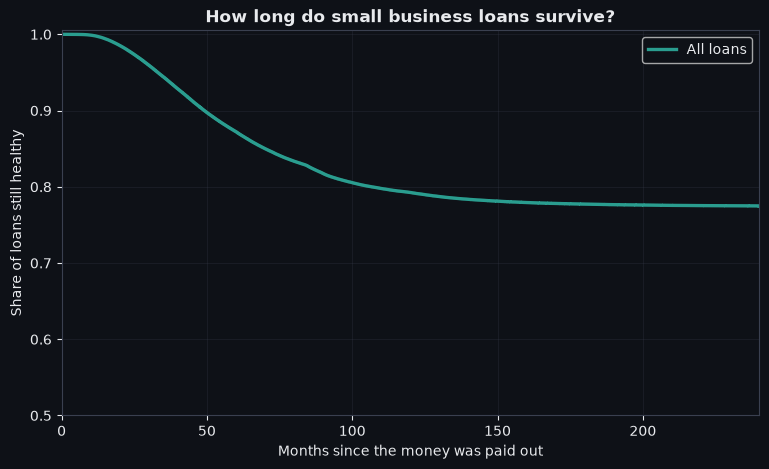

after 1 year(s): 99.8 % still healthy
after 3 year(s): 94.1 % still healthy
after 5 year(s): 87.2 % still healthy
after 10 year(s): 79.3 % still healthy


In [3]:
kaplan_meier = KaplanMeierFitter().fit(loans["duration"], loans["failed"], label="All loans")

figure, axis = plt.subplots(figsize=(9, 5))
kaplan_meier.plot_survival_function(ax=axis, color="#2a9d8f", lw=2.4, ci_alpha=0.15)
axis.set_xlim(0, 240)
axis.set_ylim(0.5, 1.005)
axis.grid(alpha=0.25)
axis.set_xlabel("Months since the money was paid out")
axis.set_ylabel("Share of loans still healthy")
axis.set_title("How long do small business loans survive?", fontweight="bold")
save_chart("19_survival_overall")

for years in [1, 3, 5, 10]:
    print("after", years, "year(s):", round(float(kaplan_meier.predict(years * 12)) * 100, 1), "% still healthy")

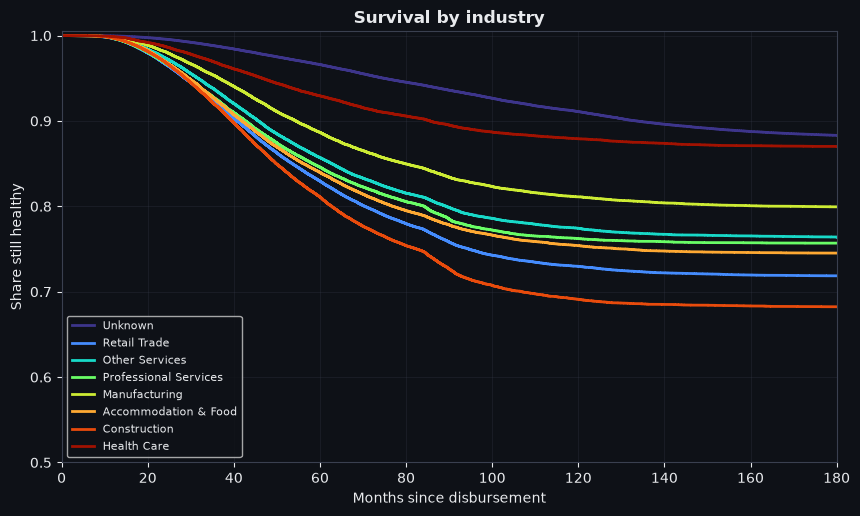

log-rank test across industries: p = 0.0


In [4]:
top_8 = loans["sector"].value_counts().head(8).index
some_loans = loans[loans["sector"].isin(top_8)]
colours = plt.cm.turbo(np.linspace(0.05, 0.95, 8))

figure, axis = plt.subplots(figsize=(10, 5.6))
for colour, industry in zip(colours, top_8):
    industry_loans = some_loans[some_loans["sector"] == industry]
    curve = KaplanMeierFitter().fit(industry_loans["duration"], industry_loans["failed"], label=industry)
    curve.plot_survival_function(ax=axis, ci_show=False, color=colour, lw=2)
axis.set_xlim(0, 180)
axis.set_ylim(0.5, 1.005)
axis.grid(alpha=0.25)
axis.legend(fontsize=8, loc="lower left")
axis.set_xlabel("Months since disbursement")
axis.set_ylabel("Share still healthy")
axis.set_title("Survival by industry", fontweight="bold")
save_chart("20_survival_by_sector")

test = multivariate_logrank_test(some_loans["duration"], some_loans["sector"], some_loans["failed"])
print("log-rank test across industries: p =", test.p_value)

## Hazard — when is a loan most likely to fail?

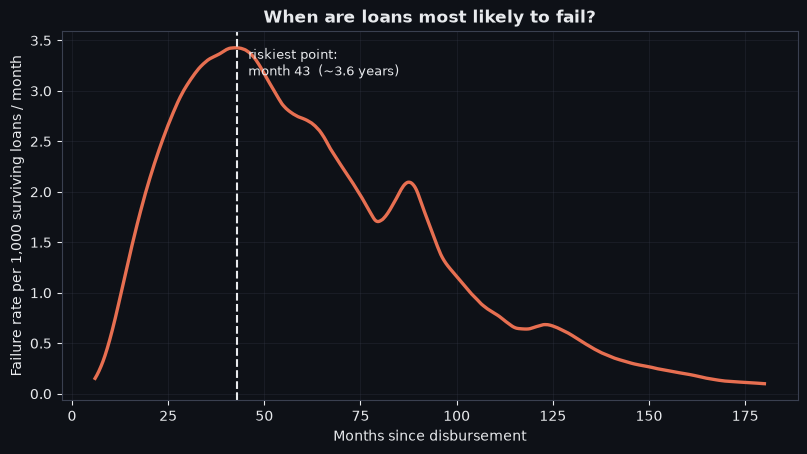

peak at month 43


In [5]:
nelson_aalen = NelsonAalenFitter().fit(loans["duration"], loans["failed"])
hazard = nelson_aalen.smoothed_hazard_(bandwidth=6).iloc[:, 0]
hazard = hazard[(hazard.index >= 6) & (hazard.index <= 180)]
peak_month = hazard.idxmax()

figure, axis = plt.subplots(figsize=(9.5, 4.8))
axis.plot(hazard.index, hazard * 1000, color="#e76f51", lw=2.4)
axis.axvline(peak_month, color="#e8eaed", ls="--")
axis.text(peak_month + 3, hazard.max() * 920,
          "riskiest point:\nmonth " + str(round(peak_month)) + "  (~" + str(round(peak_month / 12, 1)) + " years)",
          fontsize=9)
axis.set_xlabel("Months since disbursement")
axis.set_ylabel("Failure rate per 1,000 surviving loans / month")
axis.set_title("When are loans most likely to fail?", fontweight="bold")
axis.grid(alpha=0.25)
save_chart("22_hazard_rate")
print("peak at month", round(peak_month))

## Cox model — which facts make loans fail sooner?
Hazard ratio above 1 = fails sooner; below 1 = lasts longer. `Term` is left out (it sets the
censoring time, and it is leaky).

concordance: 0.7332


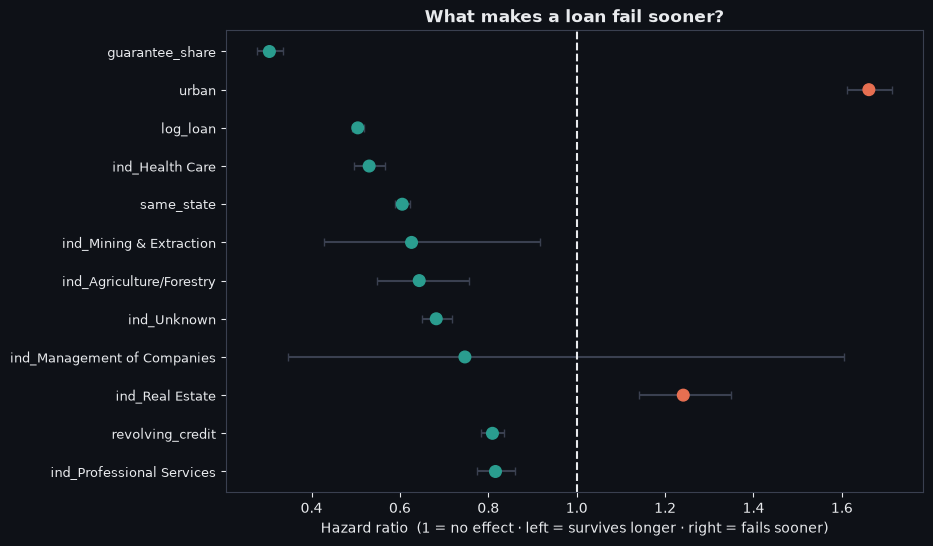

In [6]:
sample = loans.sample(150_000, random_state=train.RANDOM_SEED)
loan_amount = prep.to_number(sample["GrAppv"])
guaranteed = prep.to_number(sample["SBA_Appv"])
employees = pd.to_numeric(sample["NoEmp"], errors="coerce")

X = pd.DataFrame()
X["duration"] = sample["duration"]
X["failed"] = sample["failed"]
X["log_loan"] = np.log10(loan_amount.clip(lower=1))
X["guarantee_share"] = (guaranteed / loan_amount).replace([np.inf, -np.inf], np.nan)
X["log_employees"] = np.log10(employees.clip(lower=0) + 1)
X["new_business"] = (sample["NewExist"].str.strip() == "2").astype(int)
X["revolving_credit"] = (sample["RevLineCr"].str.strip().str.upper() == "Y").astype(int)
X["same_state"] = (sample["State"] == sample["BankState"]).astype(int)
X["urban"] = (sample["UrbanRural"].str.strip() == "1").astype(int)
industry_columns = pd.get_dummies(sample["sector"], prefix="ind", drop_first=True, dtype=float)
X = pd.concat([X, industry_columns], axis=1).dropna()

cox = CoxPHFitter(penalizer=0.01).fit(X, "duration", "failed")
print("concordance:", round(cox.concordance_index_, 4))

# the 12 strongest effects
ratios = cox.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%"]]
ratios.columns = ["ratio", "low", "high"]
strongest = (ratios["ratio"] - 1).abs().sort_values(ascending=False).index
ratios = ratios.loc[strongest].head(12)[::-1]

colours = []
for ratio in ratios["ratio"]:
    if ratio > 1:
        colours.append("#e76f51")
    else:
        colours.append("#2a9d8f")
figure, axis = plt.subplots(figsize=(9, 6))
axis.errorbar(ratios["ratio"], range(12), xerr=[ratios["ratio"] - ratios["low"], ratios["high"] - ratios["ratio"]],
              fmt="none", ecolor="#3a4050", capsize=3)
axis.scatter(ratios["ratio"], range(12), c=colours, s=70, zorder=3)
axis.axvline(1, color="#e8eaed", ls="--")
axis.set_yticks(range(12))
axis.set_yticklabels(ratios.index, fontsize=9)
axis.set_xlabel("Hazard ratio  (1 = no effect · left = survives longer · right = fails sooner)")
axis.set_title("What makes a loan fail sooner?", fontweight="bold")
save_chart("23_cox_hazard_ratios")

## Save the survival numbers the app uses

In [7]:
stats.regional()
survival = stats.survival()
print("overall riskiest month:", survival["overall"]["peak_month"], "| industries:", len(survival["by_sector"]))

overall riskiest month: 43 | industries: 19
